In [1]:
# CELL 1 — imports and environment

from pathlib import Path
from zipfile import ZipFile, BadZipFile
from io import BytesIO
import csv
import hashlib
import importlib.util
import json
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Python / pandas / NumPy ready")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("openpyxl available:", importlib.util.find_spec("openpyxl") is not None)


Python / pandas / NumPy ready
pandas: 3.1.1
NumPy: 2.4.6
openpyxl available: False


In [2]:
# CELL 2 — locate workstream and define project-level paths

cwd = Path.cwd().resolve()
search_paths = [cwd, *cwd.parents]

WORKSTREAM_ROOT = next(
    (p for p in search_paths if p.name.lower() == "ml-workstream-nasa"),
    None
)

if WORKSTREAM_ROOT is None:
    PROJECT_ROOT = next(
        (p for p in search_paths if (p / "ml-workstream-nasa").is_dir()),
        None
    )
    if PROJECT_ROOT is not None:
        WORKSTREAM_ROOT = PROJECT_ROOT / "ml-workstream-nasa"

if WORKSTREAM_ROOT is None:
    raise FileNotFoundError(
        "Could not locate ml-workstream-nasa. Put this notebook in "
        "ml-workstream-nasa/notebooks/ or start Jupyter from the workstream "
        "or its parent project folder."
    )

RAW_DIR = WORKSTREAM_ROOT / "data" / "raw" / "OSD-575"
INTERIM_DIR = WORKSTREAM_ROOT / "data" / "interim"
PROCESSED_DIR = WORKSTREAM_ROOT / "data" / "processed"
REPORTS_DIR = WORKSTREAM_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

for folder in [INTERIM_DIR, PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Current working directory:", cwd)
print("Workstream root:", WORKSTREAM_ROOT)
print("Raw OSD-575 folder:", RAW_DIR)
print("Reports folder:", REPORTS_DIR)

if not RAW_DIR.is_dir():
    raise FileNotFoundError(f"OSD-575 raw folder not found: {RAW_DIR}")


Current working directory: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\notebooks
Workstream root: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa
Raw OSD-575 folder: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\data\raw\OSD-575
Reports folder: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports


In [3]:
# CELL 3 — inventory the exact files and extensions on disk

raw_files = sorted(p for p in RAW_DIR.rglob("*") if p.is_file())

if not raw_files:
    raise FileNotFoundError(
        f"No files found in {RAW_DIR}. Check that the OSD-575 downloads "
        "were saved into this exact folder."
    )

def classify_file(path):
    name = path.name.lower()
    suffix = path.suffix.lower()

    if name.startswith(("i_", "s_", "a_")) and suffix in {".txt", ".tsv", ".csv", ""}:
        return "ISA metadata"
    if suffix in {".csv", ".tsv", ".xlsx", ".xls", ".xlsm", ".xlsb"}:
        return "Candidate assay/result table"
    if suffix == ".zip":
        return "Archive"
    if suffix in {".json"}:
        return "Manifest / metadata"
    return "Other / inspect manually"

inventory = pd.DataFrame([
    {
        "relative_path": str(p.relative_to(RAW_DIR)),
        "filename": p.name,
        "extension": p.suffix.lower() if p.suffix else "[no extension]",
        "detected_role": classify_file(p),
        "size_bytes": p.stat().st_size,
        "size_kb": round(p.stat().st_size / 1024, 2),
        "modified_time": pd.Timestamp(p.stat().st_mtime, unit="s")
    }
    for p in raw_files
])

display(inventory)
inventory.to_csv(TABLES_DIR / "osd575_raw_file_inventory.csv", index=False)

print(f"\nFiles discovered: {len(raw_files)}")
print(f"Total raw size: {inventory['size_bytes'].sum() / (1024**2):.2f} MB")
print("\nDetected extensions:")
display(inventory.groupby(["extension", "detected_role"]).size().rename("file_count").reset_index())


,relative_path,filename,extension,detected_role,size_bytes,size_kb,modified_time
0,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,.txt,ISA metadata,7973,7.79,2026-11-15 07:19:01.856678486
1,a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt,a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt,.txt,ISA metadata,10917,10.66,2026-11-15 07:19:01.881640196
2,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt,.txt,ISA metadata,11665,11.39,2026-11-15 07:19:01.868143082
3,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt,.txt,ISA metadata,13037,12.73,2026-11-15 07:19:01.861936092
4,i_Investigation.txt,i_Investigation.txt,.txt,ISA metadata,13753,13.43,2026-11-15 07:19:01.875220060
5,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,.csv,Candidate assay/result table,25275,24.68,2026-11-15 07:27:57.380322456
6,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,.csv,Candidate assay/result table,8506,8.31,2026-11-15 07:27:57.386685610
7,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,.csv,Candidate assay/result table,15241,14.88,2026-11-15 07:27:57.392768860
8,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,.xlsx,Candidate assay/result table,322799,315.23,2026-11-15 07:27:57.399227142
9,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv,.csv,Candidate assay/result table,141783,138.46,2026-11-15 07:27:57.405250788



Files discovered: 14
Total raw size: 0.70 MB

Detected extensions:


,extension,detected_role,file_count
0,.csv,Candidate assay/result table,7
1,.txt,ISA metadata,6
2,.xlsx,Candidate assay/result table,1


In [4]:
# CELL 4 — separate ISA metadata, assay tables, archives and other files

def is_isa_metadata_file(path):
    return path.name.lower().startswith(("i_", "s_", "a_"))

isa_files = [p for p in raw_files if is_isa_metadata_file(p)]
archive_files = [p for p in raw_files if p.suffix.lower() == ".zip"]
assay_files = [
    p for p in raw_files
    if not is_isa_metadata_file(p)
    and p.suffix.lower() in {".csv", ".tsv", ".txt", ".xlsx", ".xls", ".xlsm", ".xlsb"}
    and p.stat().st_size > 0
]
other_files = [
    p for p in raw_files
    if p not in isa_files and p not in archive_files and p not in assay_files
]

print("ISA metadata files:", len(isa_files))
for p in isa_files:
    print(f"  {p.name} | {p.suffix or '[no extension]'} | {p.stat().st_size:,} bytes")

print("\nCandidate assay/result files:", len(assay_files))
for p in assay_files:
    print(f"  {p.name} | {p.suffix or '[no extension]'} | {p.stat().st_size:,} bytes")

print("\nZIP archives:", len(archive_files))
for p in archive_files:
    print(" ", p.name)

print("\nOther files:", len(other_files))
for p in other_files:
    print(" ", p.name)


ISA metadata files: 6
  a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt | .txt | 7,973 bytes
  a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt | .txt | 10,917 bytes
  a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt | .txt | 11,665 bytes
  a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt | .txt | 13,037 bytes
  i_Investigation.txt | .txt | 13,753 bytes
  s_OSD-575.txt | .txt | 13,287 bytes

Candidate assay/result files: 8
  LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv | .csv | 25,275 bytes
  LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv | .csv | 8,506 bytes
  LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv | .csv | 15,241 bytes
  LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx | .xlsx | 322,799 bytes
  LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv | .csv | 141,783 bytes
  LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv | .csv | 107,418 bytes
  LSD

In [5]:
# CELL 5 — read ISA-Tab metadata text files (i_, s_, a_)

# ISA files are normally tab-delimited. Load them as strings to preserve
# identifiers, categorical values, and leading zeros.

isa_tables = {}
isa_schema_rows = []

def read_isa_text(path):
    last_error = None
    encodings = ["utf-8-sig", "utf-8", "latin-1"]
    separators = ["\\t", ",", ";"]

    for encoding in encodings:
        for sep in separators:
            try:
                frame = pd.read_csv(
                    path,
                    sep=sep,
                    dtype="string",
                    encoding=encoding,
                    keep_default_na=False,
                    engine="python"
                )
                # Prefer a parse that produces multiple columns for ISA tables.
                if frame.shape[1] > 1 or sep == separators[-1]:
                    return frame
            except Exception as exc:
                last_error = exc

    raise last_error

for path in isa_files:
    started = time.time()
    try:
        frame = read_isa_text(path)
        isa_tables[path.name] = frame
        isa_schema_rows.append({
            "filename": path.name,
            "status": "loaded",
            "rows": len(frame),
            "columns": len(frame.columns),
            "column_names": " | ".join(map(str, frame.columns)),
            "elapsed_seconds": round(time.time() - started, 3)
        })
        print(f"\nLoaded ISA file: {path.name} | shape={frame.shape}")
        display(frame.head(5))
    except Exception as exc:
        isa_schema_rows.append({
            "filename": path.name,
            "status": f"failed: {type(exc).__name__}: {exc}",
            "rows": np.nan,
            "columns": np.nan,
            "column_names": "",
            "elapsed_seconds": round(time.time() - started, 3)
        })
        print(f"FAILED: {path.name} | {type(exc).__name__}: {exc}")

isa_schema_df = pd.DataFrame(isa_schema_rows)
display(isa_schema_df)
isa_schema_df.to_csv(TABLES_DIR / "osd575_isa_metadata_schema.csv", index=False)



Loaded ISA file: a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt | shape=(28, 12)


,Sample Name,Protocol REF,Parameter Value[Sample Storage Temperature],Unit,Term Source REF,Term Accession Number,Parameter Value[Analyzer Device Name Brand Version],Assay Name,Raw Data File,Protocol REF.1,Parameter Value[Submitted Results File],Parameter Value[Transformed Files]
0,C001_serum_L-3,Comprehensive Metabolic Panel,Room Temperature,,,,Beckman Coulter AU5800,Comprehensive Metabolic Panel,Not Available,ALSDA Transformed Data,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv
1,C001_serum_L-44,Comprehensive Metabolic Panel,Room Temperature,,,,Beckman Coulter AU5800,Comprehensive Metabolic Panel,Not Available,ALSDA Transformed Data,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv
2,C001_serum_L-92,Comprehensive Metabolic Panel,Room Temperature,,,,Beckman Coulter AU5800,Comprehensive Metabolic Panel,Not Available,ALSDA Transformed Data,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv
3,C001_serum_R+1,Comprehensive Metabolic Panel,Room Temperature,,,,Beckman Coulter AU5800,Comprehensive Metabolic Panel,Not Available,ALSDA Transformed Data,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv
4,C001_serum_R+194,Comprehensive Metabolic Panel,Room Temperature,,,,Beckman Coulter AU5800,Comprehensive Metabolic Panel,Not Available,ALSDA Transformed Data,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv



Loaded ISA file: a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt | shape=(27, 16)


,Sample Name,Protocol REF,Parameter Value[Type Of Sample],Parameter Value[Sample Storage Temperature],Unit,Term Source REF,Term Accession Number,Protocol REF.1,Parameter Value[Name Of Kit],Parameter Value[Company Name],Parameter Value[Number Of Targets],Assay Name,Raw Data File,Protocol REF.2,Parameter Value[Submitted Results File],Parameter Value[Transformed Files]
0,C001_serum_L-3,Sample Preparation - Alamar Biosciences,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Alamar Biosciences,NULISA-seq 200plex v1 Inflammation Panel,Alamar Biosciences,203,Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv
1,C001_serum_L-44,Sample Preparation - Alamar Biosciences,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Alamar Biosciences,NULISA-seq 200plex v1 Inflammation Panel,Alamar Biosciences,203,Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv
2,C001_serum_L-92,Sample Preparation - Alamar Biosciences,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Alamar Biosciences,NULISA-seq 200plex v1 Inflammation Panel,Alamar Biosciences,203,Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv
3,C001_serum_R+1,Sample Preparation - Alamar Biosciences,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Alamar Biosciences,NULISA-seq 200plex v1 Inflammation Panel,Alamar Biosciences,203,Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv
4,C001_serum_R+194,Sample Preparation - Alamar Biosciences,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Alamar Biosciences,NULISA-seq 200plex v1 Inflammation Panel,Alamar Biosciences,203,Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv



Loaded ISA file: a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt | shape=(28, 15)


,Sample Name,Protocol REF,Parameter Value[Type Of Sample],Parameter Value[Sample Storage Temperature],Unit,Term Source REF,Term Accession Number,Protocol REF.1,Parameter Value[Name Of Kit],Parameter Value[Company Name],Assay Name,Raw Data File,Protocol REF.2,Parameter Value[Submitted Results File],Parameter Value[Transformed Files]
0,C001_serum_L-3,Sample Preparation - Immune HD71,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Immune HD71,Human Cytokine/Chemokine 71-Plex Discovery Assay® Array (HD71),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv
1,C001_serum_L-44,Sample Preparation - Immune HD71,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Immune HD71,Human Cytokine/Chemokine 71-Plex Discovery Assay® Array (HD71),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv
2,C001_serum_L-92,Sample Preparation - Immune HD71,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Immune HD71,Human Cytokine/Chemokine 71-Plex Discovery Assay® Array (HD71),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv
3,C001_serum_R+1,Sample Preparation - Immune HD71,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Immune HD71,Human Cytokine/Chemokine 71-Plex Discovery Assay® Array (HD71),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv
4,C001_serum_R+194,Sample Preparation - Immune HD71,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Immune HD71,Human Cytokine/Chemokine 71-Plex Discovery Assay® Array (HD71),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv



Loaded ISA file: a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt | shape=(28, 15)


,Sample Name,Protocol REF,Parameter Value[Type Of Sample],Parameter Value[Sample Storage Temperature],Unit,Term Source REF,Term Accession Number,Protocol REF.1,Parameter Value[Name Of Kit],Parameter Value[Company Name],Assay Name,Raw Data File,Protocol REF.2,Parameter Value[Submitted Results File],Parameter Value[Transformed Files]
0,C001_serum_L-3,Sample Preparation - Cardiovascular HDCVD9,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Cardiovascular HDCVD9,Human Cardiovascular Disease Panel 3 9-Plex Discovery Assay® Array (HDCVD9),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv
1,C001_serum_L-44,Sample Preparation - Cardiovascular HDCVD9,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Cardiovascular HDCVD9,Human Cardiovascular Disease Panel 3 9-Plex Discovery Assay® Array (HDCVD9),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv
2,C001_serum_L-92,Sample Preparation - Cardiovascular HDCVD9,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Cardiovascular HDCVD9,Human Cardiovascular Disease Panel 3 9-Plex Discovery Assay® Array (HDCVD9),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv
3,C001_serum_R+1,Sample Preparation - Cardiovascular HDCVD9,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Cardiovascular HDCVD9,Human Cardiovascular Disease Panel 3 9-Plex Discovery Assay® Array (HDCVD9),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv
4,C001_serum_R+194,Sample Preparation - Cardiovascular HDCVD9,Serum,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Assay Information - Cardiovascular HDCVD9,Human Cardiovascular Disease Panel 3 9-Plex Discovery Assay® Array (HDCVD9),"Eve Technologies (Calgary, Canada)",Multiplex,Not Available,ALSDA Transformed Data,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv


FAILED: i_Investigation.txt | ParserError: Expected 1 fields in line 35, saw 2

Loaded ISA file: s_OSD-575.txt | shape=(28, 25)


,Source Name,Sample Name,Characteristics[Organism],Term Source REF,Term Accession Number,Characteristics[Material Type],Term Source REF.1,Term Accession Number.1,Characteristics[Sex],Term Source REF.2,Term Accession Number.2,Factor Value[Time],Unit,Term Source REF.3,Term Accession Number.3,Factor Value[Spaceflight],Protocol REF,Protocol REF.1,Parameter Value[Sample Preservation Method],Term Source REF.4,Term Accession Number.4,Parameter Value[Sample Storage Temperature],Unit.1,Term Source REF.5,Term Accession Number.5
0,C001,C001_serum_L-3,Homo sapiens,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON/9606,Serum,NCIT,http://ncicb.nci.nih.gov/xml/owl/EVS/Thesaurus.owl#C13325,Male,MESH,http://purl.bioontology.org/ontology/MESH/D008297,Launch minus 3,day,UO,http://purl.obolibrary.org/obo/UO_0000033,Pre-flight,Treatment Protocol,sample collection,serum separator tube (SST),OSD,https://osdr.nasa.gov/,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027
1,C001,C001_serum_L-44,Homo sapiens,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON/9606,Serum,NCIT,http://ncicb.nci.nih.gov/xml/owl/EVS/Thesaurus.owl#C13325,Male,MESH,http://purl.bioontology.org/ontology/MESH/D008297,Launch minus 44,day,UO,http://purl.obolibrary.org/obo/UO_0000033,Pre-flight,Treatment Protocol,sample collection,serum separator tube (SST),OSD,https://osdr.nasa.gov/,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027
2,C001,C001_serum_L-92,Homo sapiens,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON/9606,Serum,NCIT,http://ncicb.nci.nih.gov/xml/owl/EVS/Thesaurus.owl#C13325,Male,MESH,http://purl.bioontology.org/ontology/MESH/D008297,Launch minus 92,day,UO,http://purl.obolibrary.org/obo/UO_0000033,Pre-flight,Treatment Protocol,sample collection,serum separator tube (SST),OSD,https://osdr.nasa.gov/,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027
3,C001,C001_serum_R+1,Homo sapiens,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON/9606,Serum,NCIT,http://ncicb.nci.nih.gov/xml/owl/EVS/Thesaurus.owl#C13325,Male,MESH,http://purl.bioontology.org/ontology/MESH/D008297,Return plus 1,day,UO,http://purl.obolibrary.org/obo/UO_0000033,Post-flight,Treatment Protocol,sample collection,serum separator tube (SST),OSD,https://osdr.nasa.gov/,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027
4,C001,C001_serum_R+194,Homo sapiens,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON/9606,Serum,NCIT,http://ncicb.nci.nih.gov/xml/owl/EVS/Thesaurus.owl#C13325,Male,MESH,http://purl.bioontology.org/ontology/MESH/D008297,Return plus 194,day,UO,http://purl.obolibrary.org/obo/UO_0000033,Post-flight,Treatment Protocol,sample collection,serum separator tube (SST),OSD,https://osdr.nasa.gov/,-80,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027


,filename,status,rows,columns,column_names,elapsed_seconds
0,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,loaded,28.0,12.0,Sample Name | Protocol REF | Parameter Value[Sample Storage Temperature] | Unit | Term Source REF | Term Accession N...,0.010
1,a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt,loaded,27.0,16.0,Sample Name | Protocol REF | Parameter Value[Type Of Sample] | Parameter Value[Sample Storage Temperature] | Unit | ...,0.002
2,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt,loaded,28.0,15.0,Sample Name | Protocol REF | Parameter Value[Type Of Sample] | Parameter Value[Sample Storage Temperature] | Unit | ...,0.002
3,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt,loaded,28.0,15.0,Sample Name | Protocol REF | Parameter Value[Type Of Sample] | Parameter Value[Sample Storage Temperature] | Unit | ...,0.002
4,i_Investigation.txt,"failed: ParserError: Expected 1 fields in line 35, saw 2",NaN,NaN,,0.004
5,s_OSD-575.txt,loaded,28.0,25.0,Source Name | Sample Name | Characteristics[Organism] | Term Source REF | Term Accession Number | Characteristics[Ma...,0.003


In [6]:
# CELL 6 — inspect ZIP archives without changing original files

zip_inventory_rows = []
zip_text_previews = {}

for archive in archive_files:
    print(f"\nArchive: {archive.name}")
    try:
        with ZipFile(archive) as zf:
            members = [m for m in zf.infolist() if not m.is_dir()]
            print("Members:", len(members))

            for member in members:
                zip_inventory_rows.append({
                    "archive": archive.name,
                    "member": member.filename,
                    "size_bytes": member.file_size,
                    "compressed_bytes": member.compress_size
                })

            for member in members[:60]:
                print(f"  {member.filename} ({member.file_size:,} bytes)")

            # Preview ISA-Tab text files inside the archive, without extracting them.
            for member in members:
                base = Path(member.filename).name.lower()
                if base.startswith(("i_", "s_", "a_")) and base.endswith((".txt", ".tsv")):
                    try:
                        payload = zf.read(member)
                        frame = pd.read_csv(
                            BytesIO(payload),
                            sep="\\t",
                            dtype="string",
                            encoding="utf-8-sig",
                            keep_default_na=False
                        )
                        key = f"{archive.name}::{member.filename}"
                        zip_text_previews[key] = frame
                        print(f"\nEmbedded ISA table: {member.filename} | shape={frame.shape}")
                        display(frame.head(5))
                    except Exception as exc:
                        print(f"Could not preview {member.filename}: {exc}")

    except BadZipFile:
        print("Invalid ZIP archive:", archive.name)

if zip_inventory_rows:
    pd.DataFrame(zip_inventory_rows).to_csv(
        TABLES_DIR / "osd575_zip_archive_inventory.csv",
        index=False
    )
else:
    print("No ZIP archives were downloaded. This is okay if the ISA text files are already present separately.")


No ZIP archives were downloaded. This is okay if the ISA text files are already present separately.


In [7]:
# CELL 7 — load assay/result files (CSV, TSV, TXT, Excel)

# Keep large source files untouched. This notebook loads files up to 100 MB.
# Excel workbooks are read sheet-by-sheet and each sheet is tracked separately.

MAX_LOAD_BYTES = 100 * 1024 * 1024
assay_tables = {}
assay_schema_rows = []
excel_sheet_rows = []

def read_delimited_table(path):
    suffix = path.suffix.lower()
    if suffix == ".tsv":
        separators = ["\\t", ",", ";"]
    elif suffix == ".txt":
        separators = ["\\t", ",", ";"]
    else:
        separators = [",", "\\t", ";"]

    last_error = None
    for encoding in ["utf-8-sig", "utf-8", "latin-1"]:
        for sep in separators:
            try:
                frame = pd.read_csv(
                    path,
                    sep=sep,
                    encoding=encoding,
                    low_memory=False,
                    on_bad_lines="warn"
                )
                # A single-column parse may indicate the separator was wrong.
                if frame.shape[1] > 1 or sep == separators[-1]:
                    return frame
            except Exception as exc:
                last_error = exc
    raise last_error

for path in assay_files:
    size = path.stat().st_size
    if size > MAX_LOAD_BYTES:
        assay_schema_rows.append({
            "filename": path.name,
            "sheet": "",
            "status": "skipped: larger than 100 MB",
            "rows": np.nan,
            "columns": np.nan,
            "column_names": "",
            "elapsed_seconds": 0
        })
        print(f"Skipped large file: {path.name} ({size / (1024**2):.1f} MB)")
        continue

    started = time.time()
    suffix = path.suffix.lower()

    try:
        if suffix in {".xlsx", ".xlsm", ".xls", ".xlsb"}:
            try:
                workbook = pd.ExcelFile(path)
            except ImportError as exc:
                raise ImportError(
                    "Excel engine missing. For .xlsx/.xlsm install openpyxl; "
                    "for .xls install xlrd; for .xlsb install pyxlsb."
                ) from exc

            print(f"\nWorkbook: {path.name} | sheets={workbook.sheet_names}")
            for sheet_name in workbook.sheet_names:
                frame = pd.read_excel(workbook, sheet_name=sheet_name)
                key = f"{path.name}::{sheet_name}"
                assay_tables[key] = frame
                assay_schema_rows.append({
                    "filename": path.name,
                    "sheet": sheet_name,
                    "status": "loaded",
                    "rows": len(frame),
                    "columns": len(frame.columns),
                    "column_names": " | ".join(map(str, frame.columns)),
                    "elapsed_seconds": round(time.time() - started, 3)
                })
                excel_sheet_rows.append({
                    "filename": path.name,
                    "sheet": sheet_name,
                    "rows": len(frame),
                    "columns": len(frame.columns)
                })
                print(f"  Loaded sheet {sheet_name}: {frame.shape}")
                display(frame.head(3))
        else:
            frame = read_delimited_table(path)
            assay_tables[path.name] = frame
            assay_schema_rows.append({
                "filename": path.name,
                "sheet": "",
                "status": "loaded",
                "rows": len(frame),
                "columns": len(frame.columns),
                "column_names": " | ".join(map(str, frame.columns)),
                "elapsed_seconds": round(time.time() - started, 3)
            })
            print(f"\nLoaded {path.name}: {frame.shape} in {time.time()-started:.2f}s")
            display(frame.head(3))

    except Exception as exc:
        assay_schema_rows.append({
            "filename": path.name,
            "sheet": "",
            "status": f"failed: {type(exc).__name__}: {exc}",
            "rows": np.nan,
            "columns": np.nan,
            "column_names": "",
            "elapsed_seconds": round(time.time() - started, 3)
        })
        print(f"FAILED {path.name}: {type(exc).__name__}: {exc}")

assay_schema_df = pd.DataFrame(assay_schema_rows)
display(assay_schema_df)
assay_schema_df.to_csv(TABLES_DIR / "osd575_assay_table_schema.csv", index=False)



Loaded LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv: (531, 9) in 0.00s


,ANALYTE,VALUE,RANGE_MIN,RANGE_MAX,UNITS,TEST_TYPE,SUBJECT_ID,SEX,timepoint
0,GLUCOSE,83.00,65.0,99.00,mg/dL,CMP,C001,M,L-92
1,UREA NITROGEN (BUN),25.00,7.0,25.00,mg/dL,CMP,C001,M,L-92
2,CREATININE,1.24,0.6,1.35,mg/dL,CMP,C001,M,L-92



Loaded LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv: (28, 58) in 0.00s


,Sample Name,albumin_value_gram_per_deciliter,albumin_range_min_gram_per_deciliter,albumin_range_max_gram_per_deciliter,albumin_to_globulin_ratio_value,albumin_to_globulin_ratio_range_min,albumin_to_globulin_ratio_range_max,alkaline_phosphatase_value_units_per_liter,alkaline_phosphatase_range_min_units_per_liter,alkaline_phosphatase_range_max_units_per_liter,alt_value_units_per_liter,alt_range_min_units_per_liter,alt_max_units_per_liter,ast_value_units_per_liter,ast_range_min_units_per_liter,ast_max_units_per_liter,total_bilirubin_value_milligram_per_deciliter,total_bilirubin_range_min_milligram_per_deciliter,total_bilirubin_range_max_milligram_per_deciliter,bun_to_creatinine_ratio_value,bun_to_creatinine_ratio_range_min,bun_to_creatinine_ratio_range_max,calcium_value_milligram_per_deciliter,calcium_range_min_milligram_per_deciliter,calcium_range_max_milligram_per_deciliter,carbon_dioxide_value_millimol_per_liter,carbon_dioxide_range_min_millimol_per_liter,carbon_dioxide_range_max_millimol_per_liter,chloride_value_millimol_per_liter,chloride_range_min_millimol_per_liter,chloride_range_max_millimol_per_liter,creatinine_value_milligram_per_deciliter,creatinine_range_min_milligram_per_deciliter,creatinine_range_max_milligram_per_deciliter,egfr_african_american_value_milliliter_per_minute_per_1.73_meter_squared,egfr_african_american_range_min_milliliter_per_minute_per_1.73_meter_squared,egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_value_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_min_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,globulin_value_gram_per_deciliter,globulin_range_min_gram_per_deciliter,globulin_range_max_gram_per_deciliter,glucose_value_milligram_per_deciliter,glucose_range_min_milligram_per_deciliter,glucose_range_max_milligram_per_deciliter,potassium_value_millimol_per_liter,potassium_range_min_millimol_per_liter,potassium_range_max_millimol_per_liter,total_protein_value_gram_per_deciliter,total_protein_range_min_gram_per_deciliter,total_protein_range_max_gram_per_deciliter,sodium_value_millimol_per_liter,sodium_range_min_millimol_per_liter,sodium_range_max_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter,urea_nitrogen_bun_range_min_milligram_per_deciliter,urea_nitrogen_bun_range_max_milligram_per_deciliter
0,C001_serum_L-3,4.9,3.6,5.1,2.0,1,2.5,45,36,130,13,9,46,15,10,40,1.0,0.2,1.2,15.0,6.0,22.0,9.6,8.6,10.3,26,20,32,102,98,110,1.37,0.6,1.35,75,60,NaN,65,60,NaN,2.5,1.9,3.7,69,65,99,3.9,3.5,5.3,7.4,6.1,8.1,142,135,146,20,7,25
1,C001_serum_L-44,5.0,3.6,5.1,1.9,1,2.5,46,36,130,16,9,46,18,10,40,0.9,0.2,1.2,NaN,6.0,22.0,10.0,8.6,10.3,26,20,32,101,98,110,1.10,0.6,1.35,98,60,NaN,85,60,NaN,2.7,1.9,3.7,80,65,99,4.2,3.5,5.3,7.7,6.1,8.1,139,135,146,19,7,25
2,C001_serum_L-92,5.0,3.6,5.1,2.2,1,2.5,51,36,130,15,9,46,15,10,40,0.7,0.2,1.2,NaN,6.0,22.0,9.7,8.6,10.3,23,20,32,104,98,110,1.24,0.6,1.35,85,60,NaN,73,60,NaN,2.3,1.9,3.7,83,65,99,4.6,3.5,5.3,7.3,6.1,8.1,141,135,146,25,7,25



Loaded LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv: (252, 8) in 0.01s


,Analyte,Concentration,Timepoint,ID,Unit,Timepoint2,Type,Percent
0,a-2 Macroglobulin,903742.69,L-92,C001,ng/ml,Preflight,HDCVD9,61.947276
1,a-2 Macroglobulin,2036900.00,L-92,C002,ng/ml,Preflight,HDCVD9,139.619837
2,a-2 Macroglobulin,3030400.00,L-92,C003,ng/ml,Preflight,HDCVD9,207.719551


... (5 outputs left out)

,Sample Name,a2_macroglobulin_concentration_nanogram_per_milliliter,a2_macroglobulin_percent,agp_concentration_nanogram_per_milliliter,agp_percent,crp_concentration_picogram_per_milliliter,crp_percent,fetuin_a36_concentration_nanogram_per_milliliter,fetuin_a36_percent,fibrinogen_concentration_nanogram_per_milliliter,fibrinogen_percent,haptoglobin_concentration_nanogram_per_milliliter,haptoglobin_percent,l_selectin_concentration_picogram_per_milliliter,l_selectin_percent,pf4_concentration_nanogram_per_milliliter,pf4_percent,sap_concentration_picogram_per_milliliter,sap_percent
0,C001_serum_L-3,1002300.00,68.702912,1214100.0,56.505028,5131700,28.972195,155302.07,63.401726,2780.38,65.861344,1305900.00,22.434959,561452.93,57.944587,8602.35,74.659519,6057300,66.132482
1,C001_serum_L-44,657943.56,45.098911,1745700.0,81.246049,2191000,12.369795,194978.74,79.599639,5707.32,135.194386,122441.48,2.103507,675114.37,69.674983,3903.78,33.880781,5428000,59.261901
2,C001_serum_L-92,903742.69,61.947276,1048700.0,48.807201,18385000,103.796754,144424.41,58.960946,3208.77,76.009001,1049100.00,18.023214,515957.20,53.249214,6973.32,60.521220,4760000,51.968801



Loaded LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv: (28, 143) in 0.00s


,Sample Name,6ckine_concentration_picogram_per_milliliter,6ckine_percent,bca_1_concentration_picogram_per_milliliter,bca_1_percent,ctack_concentration_picogram_per_milliliter,ctack_percent,egf_concentration_picogram_per_milliliter,egf_percent,ena_78_concentration_picogram_per_milliliter,ena_78_percent,eotaxin_concentration_picogram_per_milliliter,eotaxin_percent,eotaxin_2_concentration_picogram_per_milliliter,eotaxin_2_percent,eotaxin_3_concentration_picogram_per_milliliter,eotaxin_3_percent,fgf_2_concentration_picogram_per_milliliter,fgf_2_percent,flt_3l_concentration_picogram_per_milliliter,flt_3l_percent,fractalkine_concentration_picogram_per_milliliter,fractalkine_percent,g_csf_concentration_picogram_per_milliliter,g_csf_percent,gm_csf_concentration_picogram_per_milliliter,gm_csf_percent,groα_concentration_picogram_per_milliliter,groα_percent,i_309_concentration_picogram_per_milliliter,i_309_percent,ifn_α2_concentration_picogram_per_milliliter,ifn_α2_percent,ifnγ_concentration_picogram_per_milliliter,ifnγ_percent,il_10_concentration_picogram_per_milliliter,il_10_percent,il_12p40_concentration_picogram_per_milliliter,il_12p40_percent,il_12p70_concentration_picogram_per_milliliter,il_12p70_percent,il_13_concentration_picogram_per_milliliter,il_13_percent,il_15_concentration_picogram_per_milliliter,il_15_percent,il_16_concentration_picogram_per_milliliter,il_16_percent,il_17a_concentration_picogram_per_milliliter,il_17a_percent,il_17e_per_il_25_concentration_picogram_per_milliliter,...,lif_concentration_picogram_per_milliliter,lif_percent,m_csf_concentration_picogram_per_milliliter,m_csf_percent,mcp_1_concentration_picogram_per_milliliter,mcp_1_percent,mcp_2_concentration_picogram_per_milliliter,mcp_2_percent,mcp_3_concentration_picogram_per_milliliter,mcp_3_percent,mcp_4_concentration_picogram_per_milliliter,mcp_4_percent,mdc_concentration_picogram_per_milliliter,mdc_percent,mig_per_cxcl9_concentration_picogram_per_milliliter,mig_per_cxcl9_percent,mip_1α_concentration_picogram_per_milliliter,mip_1α_percent,mip_1β_concentration_picogram_per_milliliter,mip_1β_percent,mip_1δ_concentration_picogram_per_milliliter,mip_1δ_percent,pdgf_aa_concentration_picogram_per_milliliter,pdgf_aa_percent,pdgf_ab_per_bb_concentration_picogram_per_milliliter,pdgf_ab_per_bb_percent,rantes_concentration_picogram_per_milliliter,rantes_percent,scd40l_concentration_picogram_per_milliliter,scd40l_percent,scf_concentration_picogram_per_milliliter,scf_percent,sdf_1α_plus_β_concentration_picogram_per_milliliter,sdf_1α_plus_β_percent,tarc_concentration_picogram_per_milliliter,tarc_percent,tgfα_concentration_picogram_per_milliliter,tgfα_percent,tnfα_concentration_picogram_per_milliliter,tnfα_percent,tnfβ_concentration_picogram_per_milliliter,tnfβ_percent,tpo_concentration_picogram_per_milliliter,tpo_percent,trail_concentration_picogram_per_milliliter,trail_percent,tslp_concentration_picogram_per_milliliter,tslp_percent,vegf_a_concentration_picogram_per_milliliter,vegf_a_percent
0,C001_serum_L-3,909.52,87.230109,72.49,144.748403,1439.51,134.778429,916.85,184.263679,1526.33,155.164378,50.62,52.487233,1508.62,198.493273,26.62,56.432180,173.13,91.818957,23.47,130.642917,300.53,47.184087,59.56,89.310974,65.09,12.792888,35.62,86.267861,1.40,66.561014,201.71,167.467154,3.05,10.331687,7.07,75.554368,144.21,91.927670,15.38,24.764179,142.58,58.990687,8.44,114.118310,274.84,119.955045,24.47,105.307703,2123.17,...,11.12,22.443110,243.05,139.536886,1102.50,124.548242,58.57,133.958488,22.98,32.230391,94.22,75.301201,2801.86,174.616320,3063.44,133.844468,79.25,93.595914,72.43,86.306675,5087.16,121.681918,1235.59,13.659555,251163.70,197.814489,2602.42,73.874951,24009.05,162.435025,51.62,76.496740,6656.76,90.154302,137.87,121.440158,32.88,127.660401,68.71,38.307896,14.80,13.271261,993.21,106.186298,109.03,167.270961,9.52,74.234843,943.22,133.873307
1,C001_serum_L-44,844.40,80.984590,49.83,99.500799,1134.00,106.174142,438.11,88.049038,994.81,101.130866,27.05,28.047801,773.57

,filename,sheet,status,rows,columns,column_names,elapsed_seconds
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,,loaded,531.0,9.0,ANALYTE | VALUE | RANGE_MIN | RANGE_MAX | UNITS | TEST_TYPE | SUBJECT_ID | SEX | timepoint,0.002
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,,loaded,28.0,58.0,Sample Name | albumin_value_gram_per_deciliter | albumin_range_min_gram_per_deciliter | albumin_range_max_gram_per_d...,0.002
2,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,,loaded,252.0,8.0,Analyte | Concentration | Timepoint | ID | Unit | Timepoint2 | Type | Percent,0.014
3,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,,failed: ImportError: Excel engine missing. For .xlsx/.xlsm install openpyxl; for .xls install xlrd; for .xlsb instal...,NaN,NaN,,0.002
4,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv,,loaded,27.0,407.0,Sample ID | activin_a_concentration_npq | activin_a_percent_normalized_value | activin_ab_concentration_npq | activi...,0.004
5,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,,loaded,1988.0,8.0,Analyte | Concentration | Timepoint | ID | Unit | Timepoint2 | Type | Percent,0.004
6,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv,,loaded,28.0,19.0,Sample Name | a2_macroglobulin_concentration_nanogram_per_milliliter | a2_macroglobulin_percent | agp_concentration_...,0.003
7,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv,,loaded,28.0,143.0,Sample Name | 6ckine_concentration_picogram_per_milliliter | 6ckine_percent | bca_1_concentration_picogram_per_milli...,0.002


In [8]:
# CELL 8 — identify likely subject, sample, timepoint and biomarker columns

identity_patterns = re.compile(
    r"(subject|participant|crew|astronaut|sample|specimen|biospecimen|"
    r"time.?point|collection|visit|flight|mission|study|characteristic|factor)",
    flags=re.IGNORECASE
)
measurement_patterns = re.compile(
    r"(analyte|biomarker|protein|cytokine|chemokine|metabolite|"
    r"result|concentration|value|measurement|unit|panel)",
    flags=re.IGNORECASE
)

column_map_rows = []

for table_name, frame in {**isa_tables, **assay_tables}.items():
    for col in frame.columns:
        col_text = str(col)
        if identity_patterns.search(col_text) or measurement_patterns.search(col_text):
            column_map_rows.append({
                "table": table_name,
                "column": col_text,
                "possible_role": (
                    "identity / sample / timepoint metadata"
                    if identity_patterns.search(col_text)
                    else "possible biomarker / measurement field"
                ),
                "dtype": str(frame[col].dtype)
            })

column_map_df = pd.DataFrame(column_map_rows)
if not column_map_df.empty:
    display(column_map_df)
    column_map_df.to_csv(TABLES_DIR / "osd575_candidate_identity_measurement_columns.csv", index=False)
else:
    print("No columns matched the initial name patterns. Review table schemas manually.")


,table,column,possible_role,dtype
0,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,Sample Name,identity / sample / timepoint metadata,string
1,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,Parameter Value[Sample Storage Temperature],identity / sample / timepoint metadata,string
2,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,Unit,possible biomarker / measurement field,string
3,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,Parameter Value[Analyzer Device Name Brand Version],possible biomarker / measurement field,string
4,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,Parameter Value[Submitted Results File],possible biomarker / measurement field,string
...,...,...,...,...
568,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv,tnfβ_concentration_picogram_per_milliliter,possible biomarker / measurement field,float64
569,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv,tpo_concentration_picogram_per_milliliter,possible biomarker / measurement field,float64
570,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv,trail_concentration_picogram_per_milliliter,possible biomarker / measurement field,float64
571,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv,tslp_concentration_picogram_per_milliliter,possible biomarker / measurement field,float64


In [9]:
# CELL 9 — data-quality summary for every loaded assay table

missingness_rows = []
duplicate_rows = []
numeric_summary_rows = []
dtype_rows = []

for table_name, frame in assay_tables.items():
    for col in frame.columns:
        series = frame[col]
        dtype_rows.append({
            "table": table_name,
            "column": str(col),
            "dtype": str(series.dtype),
            "non_null": int(series.notna().sum()),
            "null": int(series.isna().sum())
        })
        missingness_rows.append({
            "table": table_name,
            "column": str(col),
            "rows": len(frame),
            "missing_count": int(series.isna().sum()),
            "missing_percent": round(float(series.isna().mean() * 100), 3)
        })

        numeric = pd.to_numeric(series, errors="coerce")
        if numeric.notna().sum() > 0:
            numeric_summary_rows.append({
                "table": table_name,
                "column": str(col),
                "numeric_count": int(numeric.notna().sum()),
                "missing_or_nonnumeric": int(numeric.isna().sum()),
                "minimum": float(numeric.min()),
                "median": float(numeric.median()),
                "mean": float(numeric.mean()),
                "maximum": float(numeric.max())
            })

    duplicate_rows.append({
        "table": table_name,
        "rows": len(frame),
        "duplicate_full_rows": int(frame.duplicated().sum())
    })

missingness_df = pd.DataFrame(missingness_rows)
duplicates_df = pd.DataFrame(duplicate_rows)
numeric_summary_df = pd.DataFrame(numeric_summary_rows)
dtype_df = pd.DataFrame(dtype_rows)

display(duplicates_df)
display(missingness_df.sort_values(["table", "missing_percent"], ascending=[True, False]).head(50))
display(numeric_summary_df.head(50))

missingness_df.to_csv(TABLES_DIR / "osd575_column_missingness.csv", index=False)
duplicates_df.to_csv(TABLES_DIR / "osd575_duplicate_row_summary.csv", index=False)
numeric_summary_df.to_csv(TABLES_DIR / "osd575_numeric_column_summary.csv", index=False)
dtype_df.to_csv(TABLES_DIR / "osd575_column_dtypes.csv", index=False)


,table,rows,duplicate_full_rows
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,531,0
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,28,0
2,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,252,0
3,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv,27,0
4,LSDS-8_Multiplex_serum.immune.EvePanel_SUBMITTED.csv,1988,0
5,LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv,28,0
6,LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv,28,0


,table,column,rows,missing_count,missing_percent
3,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,RANGE_MAX,531,56,10.546
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,VALUE,531,22,4.143
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,ANALYTE,531,0,0.000
2,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,RANGE_MIN,531,0,0.000
4,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,UNITS,531,0,0.000
5,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,TEST_TYPE,531,0,0.000
6,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,SUBJECT_ID,531,0,0.000
7,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,SEX,531,0,0.000
8,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,timepoint,531,0,0.000
45,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28,28,100.000


,table,column,numeric_count,missing_or_nonnumeric,minimum,median,mean,maximum
0,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,VALUE,509,22,0.20,17.00,36.314912,143.00
1,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,RANGE_MIN,531,0,0.20,8.60,27.926365,135.00
2,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,RANGE_MAX,475,56,1.05,22.00,40.222316,153.00
3,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,albumin_value_gram_per_deciliter,28,0,4.20,4.55,4.589286,5.10
4,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,albumin_range_min_gram_per_deciliter,28,0,3.60,3.60,3.600000,3.60
5,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,albumin_range_max_gram_per_deciliter,28,0,5.10,5.10,5.100000,5.10
6,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,albumin_to_globulin_ratio_value,28,0,1.30,1.60,1.664286,2.20
7,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,albumin_to_globulin_ratio_range_min,28,0,1.00,1.00,1.000000,1.00
8,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,albumin_to_globulin_ratio_range_max,28,0,2.50,2.50,2.500000,2.50
9,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,alkaline_phosphatase_value_units_per_liter,28,0,31.00,53.00,54.178571,78.00


In [10]:
# CELL 10 — inspect ISA sample metadata for subjects and collection timepoints

# We do not force labels such as PRE/POST unless those labels are present in the source.
# This cell prints likely sample/subject/timepoint fields for manual verification.

for table_name, frame in isa_tables.items():
    print(f"\n--- {table_name} ---")
    if frame.empty:
        print("Empty table")
        continue

    candidate_cols = [
        c for c in frame.columns
        if identity_patterns.search(str(c))
    ]

    if candidate_cols:
        display(frame[candidate_cols].head(30))
    else:
        print("No obvious identity/timepoint column names. Full header:")
        print(list(frame.columns))

# Also show candidate fields from assay result tables.
for table_name, frame in assay_tables.items():
    candidate_cols = [
        c for c in frame.columns
        if identity_patterns.search(str(c))
    ]
    if candidate_cols:
        print(f"\nLikely sample/subject fields in {table_name}:")
        display(frame[candidate_cols].head(10))



--- a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt ---


,Sample Name,Parameter Value[Sample Storage Temperature]
0,C001_serum_L-3,Room Temperature
1,C001_serum_L-44,Room Temperature
2,C001_serum_L-92,Room Temperature
3,C001_serum_R+1,Room Temperature
4,C001_serum_R+194,Room Temperature
5,C001_serum_R+45,Room Temperature
6,C001_serum_R+82,Room Temperature
7,C002_serum_L-3,Room Temperature
8,C002_serum_L-44,Room Temperature
9,C002_serum_L-92,Room Temperature



--- a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt ---


,Sample Name,Parameter Value[Type Of Sample],Parameter Value[Sample Storage Temperature]
0,C001_serum_L-3,Serum,-80
1,C001_serum_L-44,Serum,-80
2,C001_serum_L-92,Serum,-80
3,C001_serum_R+1,Serum,-80
4,C001_serum_R+194,Serum,-80
5,C001_serum_R+45,Serum,-80
6,C001_serum_R+82,Serum,-80
7,C002_serum_L-3,Serum,-80
8,C002_serum_L-44,Serum,-80
9,C002_serum_L-92,Serum,-80



--- a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt ---


,Sample Name,Parameter Value[Type Of Sample],Parameter Value[Sample Storage Temperature]
0,C001_serum_L-3,Serum,-80
1,C001_serum_L-44,Serum,-80
2,C001_serum_L-92,Serum,-80
3,C001_serum_R+1,Serum,-80
4,C001_serum_R+194,Serum,-80
5,C001_serum_R+45,Serum,-80
6,C001_serum_R+82,Serum,-80
7,C002_serum_L-3,Serum,-80
8,C002_serum_L-44,Serum,-80
9,C002_serum_L-92,Serum,-80


... (14 outputs left out)


Likely sample/subject fields in LSDS-8_Multiplex_serum_cardiovascular_EvePanel_TRANSFORMED.csv:


,Sample Name
0,C001_serum_L-3
1,C001_serum_L-44
2,C001_serum_L-92
3,C001_serum_R+1
4,C001_serum_R+194
5,C001_serum_R+45
6,C001_serum_R+82
7,C002_serum_L-3
8,C002_serum_L-44
9,C002_serum_L-92



Likely sample/subject fields in LSDS-8_Multiplex_serum_immune_EvePanel_TRANSFORMED.csv:


,Sample Name
0,C001_serum_L-3
1,C001_serum_L-44
2,C001_serum_L-92
3,C001_serum_R+1
4,C001_serum_R+194
5,C001_serum_R+45
6,C001_serum_R+82
7,C002_serum_L-3
8,C002_serum_L-44
9,C002_serum_L-92


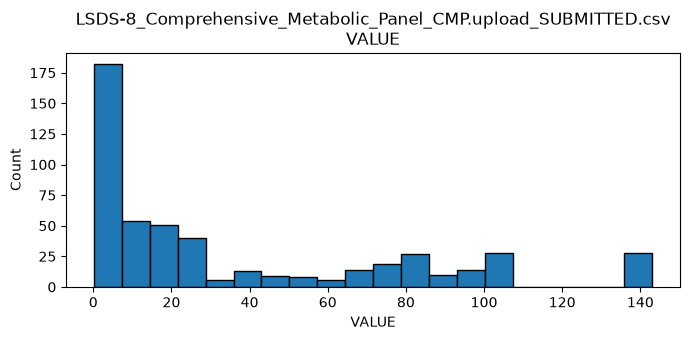

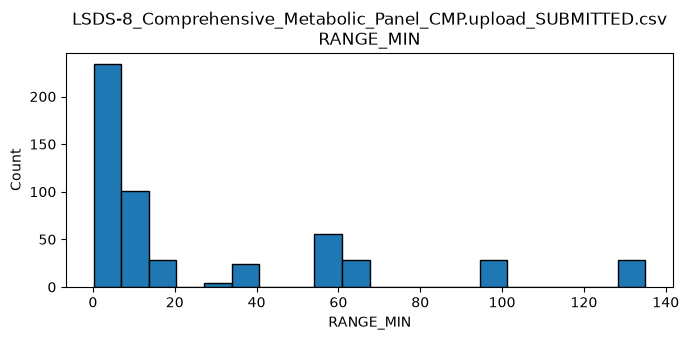

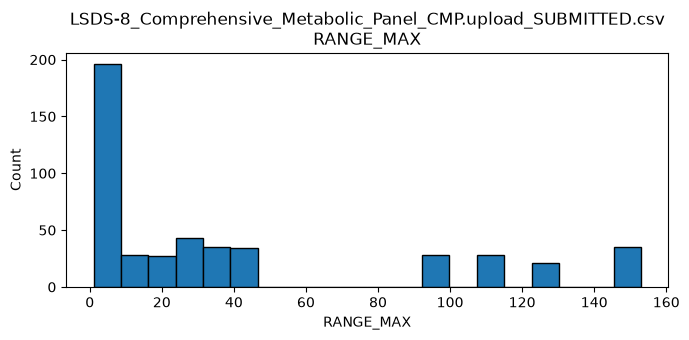

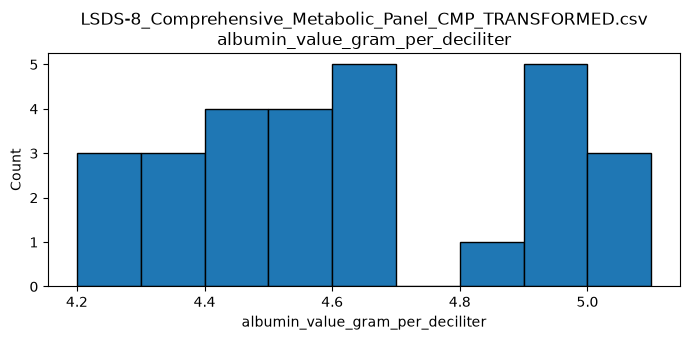

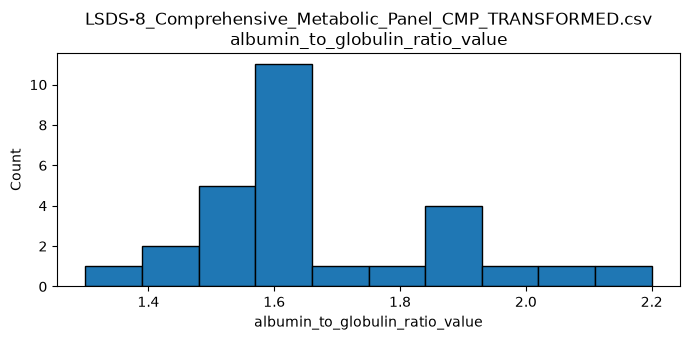

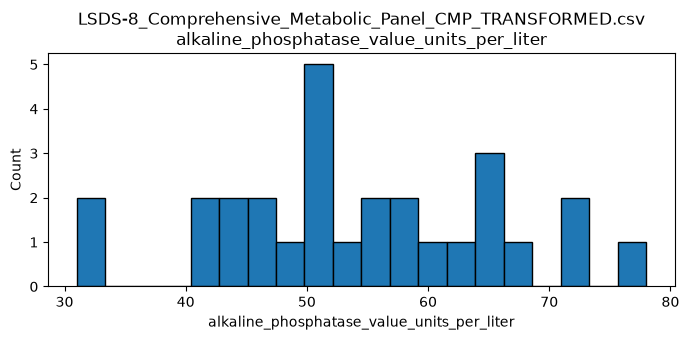

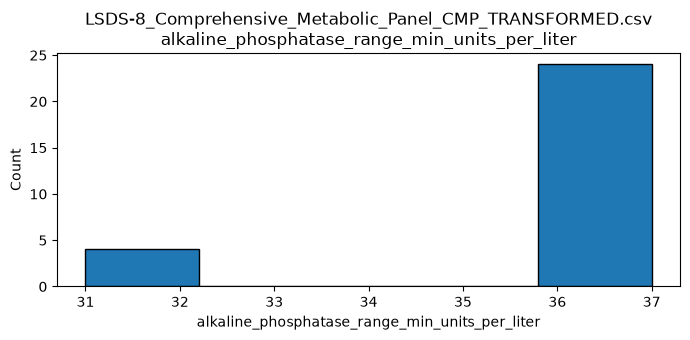

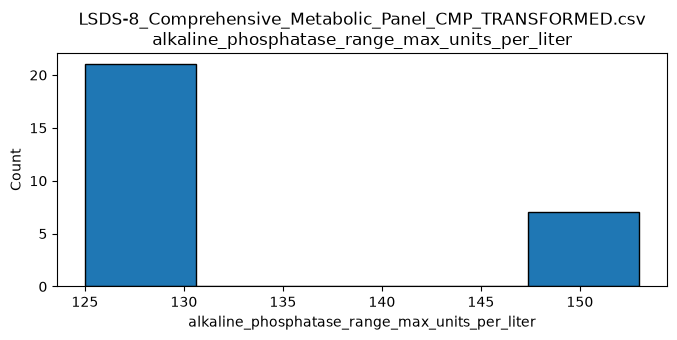

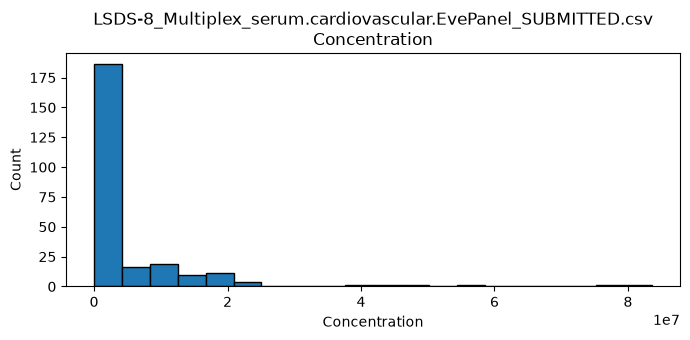

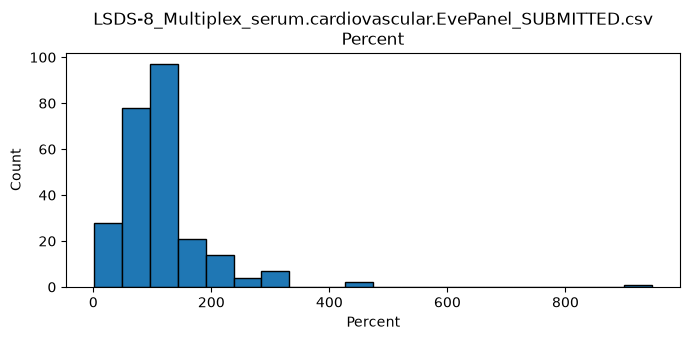

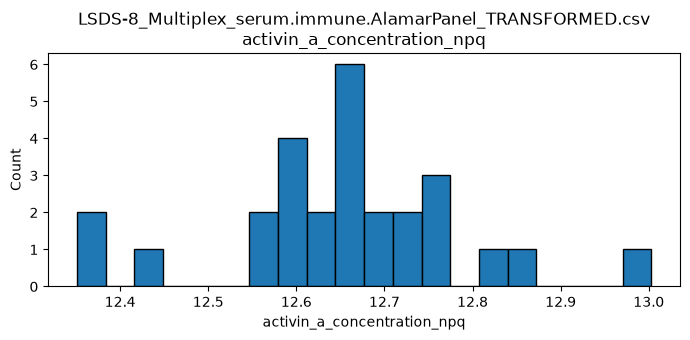

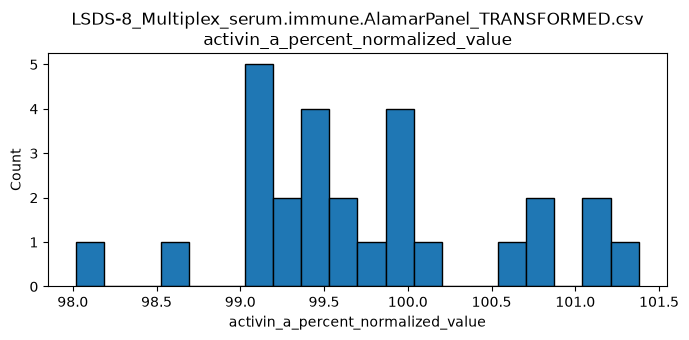

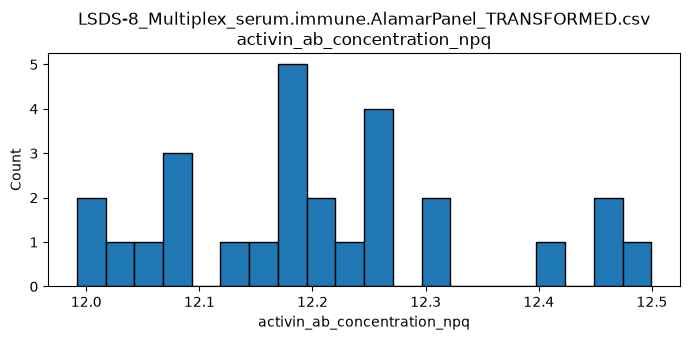

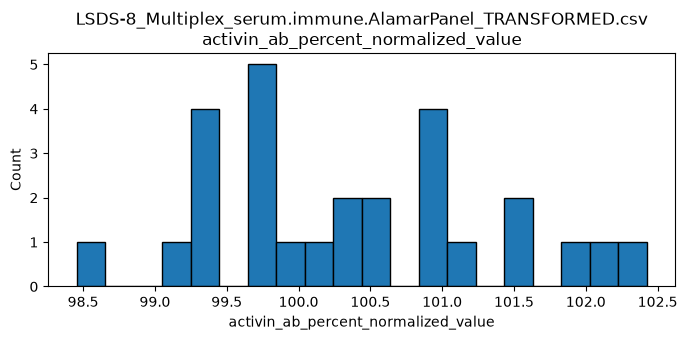

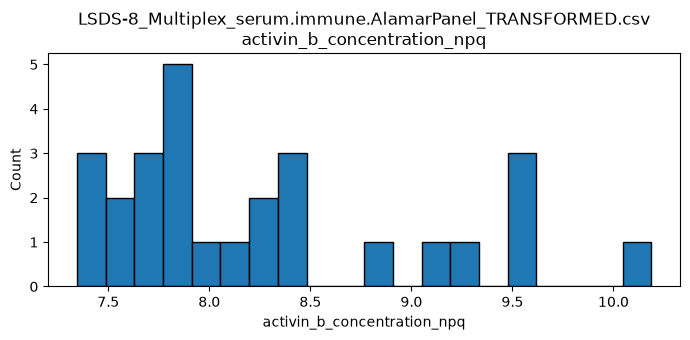

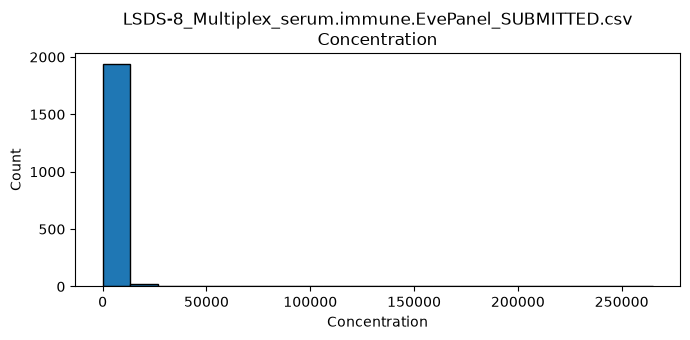

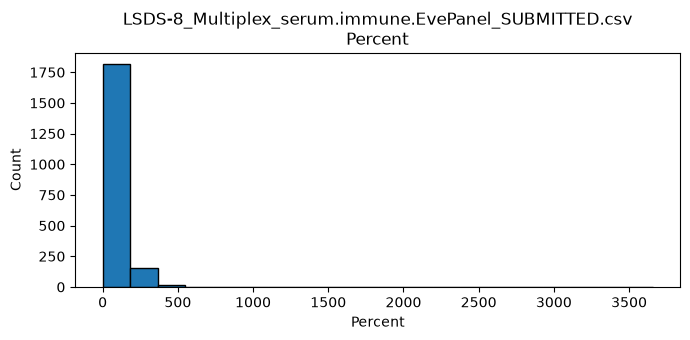

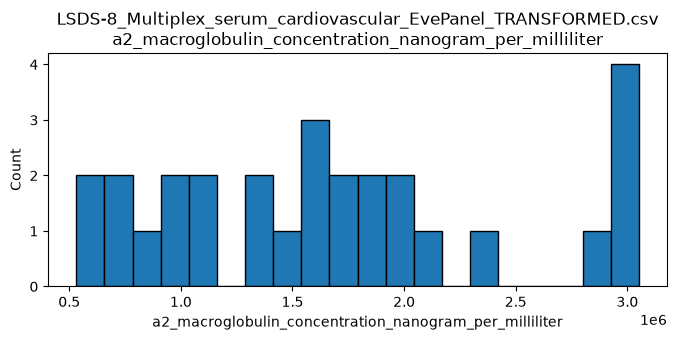

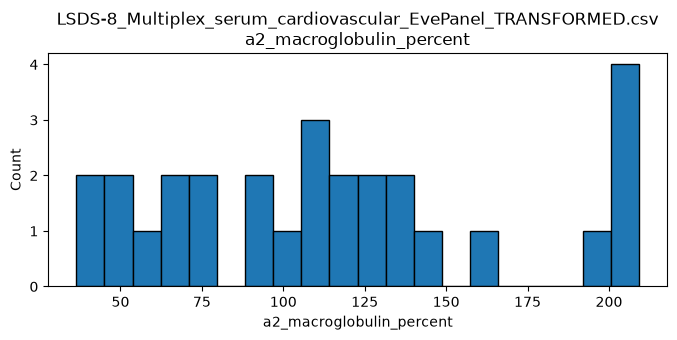

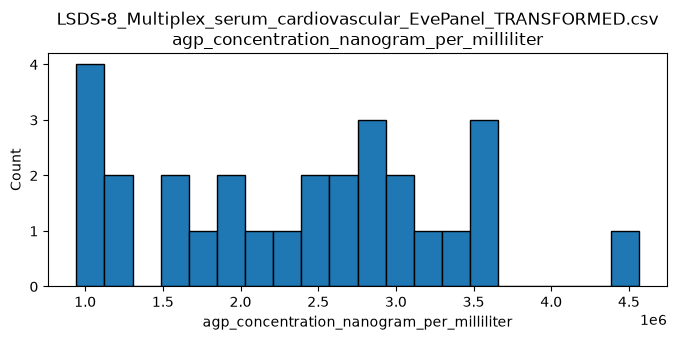

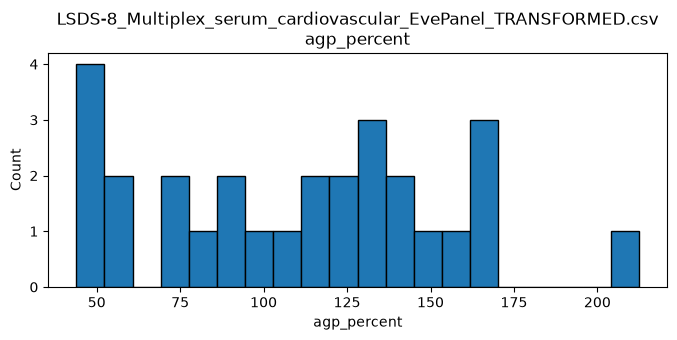

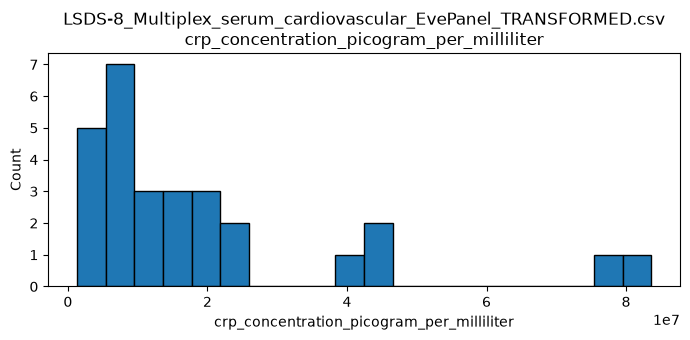

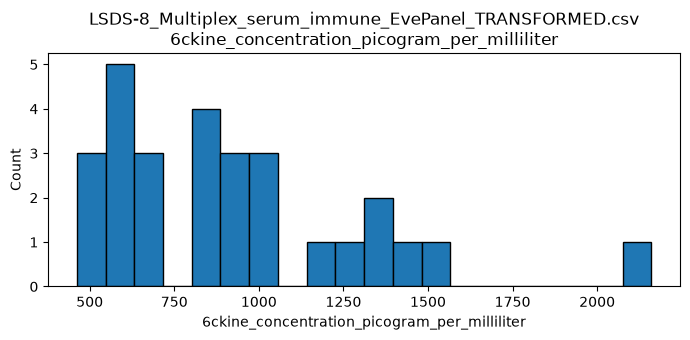

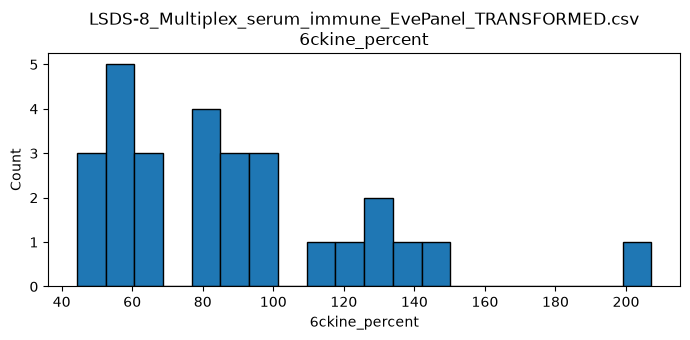

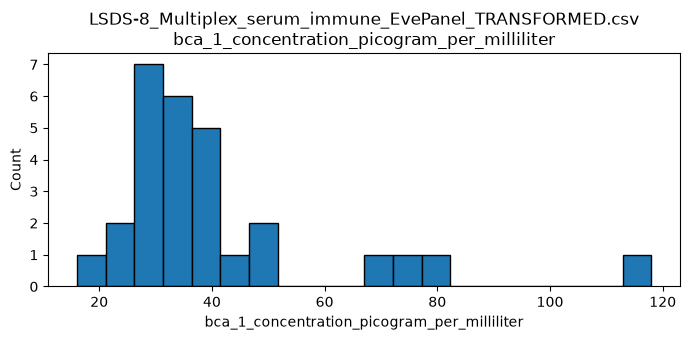

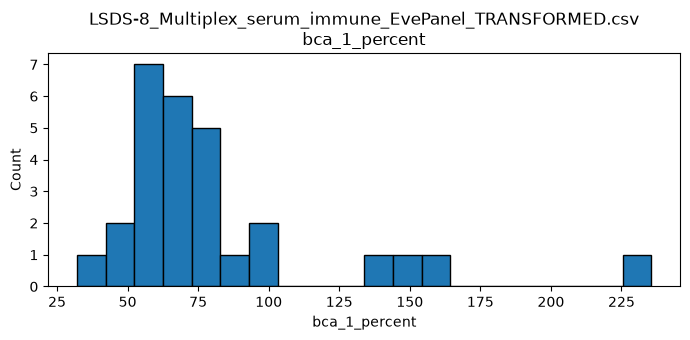

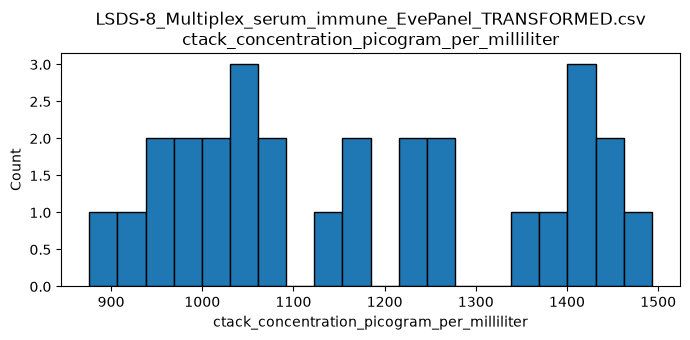

In [11]:
# CELL 11 — simple numeric distribution plots for assay tables

# These are descriptive plots only. No clinical reference ranges are imposed.
# Limit to the first 8 numeric columns per table to keep the audit manageable.

for table_name, frame in assay_tables.items():
    numeric_cols = []
    for col in frame.columns:
        converted = pd.to_numeric(frame[col], errors="coerce")
        if converted.notna().sum() >= 3 and converted.nunique(dropna=True) > 1:
            numeric_cols.append(col)

    if not numeric_cols:
        print(f"No numeric columns suitable for plots: {table_name}")
        continue

    for col in numeric_cols[:5]:
        values = pd.to_numeric(frame[col], errors="coerce").dropna()
        if values.empty:
            continue

        plt.figure(figsize=(7, 3.5))
        plt.hist(values, bins=min(20, max(5, values.nunique())), edgecolor="black")
        plt.title(f"{table_name}\n{col}")
        plt.xlabel(str(col))
        plt.ylabel("Count")
        plt.tight_layout()

        safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", f"{table_name}_{col}")[:120]
        plt.savefig(FIGURES_DIR / f"distribution_{safe_name}.png", dpi=140, bbox_inches="tight")
        plt.show()
        plt.close()


In [12]:
# CELL 12 — SHA-256 fingerprints of original files

# This does not alter files. Hashing helps establish whether an original changes later.
# These files are small in your screenshot, so hashing should be quick.

checksum_rows = []

for path in raw_files:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)

    checksum_rows.append({
        "relative_path": str(path.relative_to(RAW_DIR)),
        "filename": path.name,
        "size_bytes": path.stat().st_size,
        "sha256": digest.hexdigest()
    })

checksums_df = pd.DataFrame(checksum_rows)
display(checksums_df)
checksums_df.to_csv(TABLES_DIR / "osd575_raw_sha256_checksums.csv", index=False)


,relative_path,filename,size_bytes,sha256
0,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,a_OSD-575_analytical-chemistry_comprehensive-metabolic-panel_quest diagnostics.txt,7973,49679b6d4d4c8457441b1dc9d27e0d7ea600dc14bd1c2726f58b09e744c2cff5
1,a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt,a_OSD-575_immunoassay_multiplex_Alamar Biosciences.txt,10917,1a8d3eb9f1b7382c58061feba22f371e041fb36ca98e844c02b5a723759a0882
2,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HD71.txt,11665,1c47600b35550a98dc89aa1d444df0dc6a97980923f8598c56ca7ddaab4d74d6
3,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt,a_OSD-575_immunoassay_multiplex_Eve Technologies Panel HDCVD9.txt,13037,4e5f6a3351d53eb8edca95236caf874d68f54655e58c9abe0446c6ed33821700
4,i_Investigation.txt,i_Investigation.txt,13753,1ffb9686ef2ffc6156bb7208434394740a1670c9ff2eb3845d095efca2f48d02
5,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP.upload_SUBMITTED.csv,25275,dab247eb794edab59aaaa683c85fd1f2dbf4ae3684872739338e10ead4192a0c
6,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv,8506,5eb1e7f025dd8443a9e70111e62bc32afae3432753024489c5c013e401d709d9
7,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,LSDS-8_Multiplex_serum.cardiovascular.EvePanel_SUBMITTED.csv,15241,a6422f9b13099f7a220fb1743be71ba1fa3b733ef26318c6c345abc3a295e96c
8,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,LSDS-8_Multiplex_serum.immune.AlamarPanel_SUBMITTED.xlsx,322799,3f2243ab8d4e7913c1eacde842e036b184682e627cb480734c272ae098444a5d
9,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv,LSDS-8_Multiplex_serum.immune.AlamarPanel_TRANSFORMED.csv,141783,b53bcf9c325ae1d86e6d0d16df31ddd123423f449c7d550ac026ee01659241bc


In [13]:
# CELL 13 — generate the dataset audit report (no extra markdown-table dependency)

def markdown_table(frame, columns=None, max_rows=100):
    if frame is None or frame.empty:
        return "_No rows._"
    view = frame.copy()
    if columns is not None:
        view = view[columns]
    view = view.head(max_rows).fillna("")
    headers = [str(c) for c in view.columns]
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]
    for row in view.itertuples(index=False, name=None):
        values = [str(v).replace("|", "\\|").replace("\n", " ") for v in row]
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)

report_lines = [
    "# NASA OSD-575 Dataset Audit",
    "",
    f"- Audit timestamp: {pd.Timestamp.now().isoformat(timespec='seconds')}",
    f"- Raw directory: `{RAW_DIR}`",
    f"- Files discovered: {len(raw_files)}",
    f"- Total raw size: {inventory['size_bytes'].sum() / (1024**2):.2f} MB",
    f"- ISA metadata files: {len(isa_files)}",
    f"- Candidate assay/result files: {len(assay_files)}",
    f"- ZIP archives: {len(archive_files)}",
    "",
    "## Raw file inventory",
    "",
    markdown_table(inventory, ["filename", "extension", "detected_role", "size_kb"]),
    "",
    "## ISA metadata tables",
    "",
    (markdown_table(isa_schema_df, ["filename", "status", "rows", "columns"])
     if not isa_schema_df.empty else "No ISA metadata tables were loaded."),
    "",
    "## Assay/result tables",
    "",
    (markdown_table(assay_schema_df, ["filename", "sheet", "status", "rows", "columns"])
     if not assay_schema_df.empty else "No assay/result tables were loaded."),
    "",
    "## Duplicate row summary",
    "",
    (markdown_table(duplicates_df) if not duplicates_df.empty else "No assay tables loaded."),
    "",
    "## Important interpretation safeguards",
    "",
    "- This audit reports source-file structure and descriptive data quality; it does not infer clinical normality.",
    "- Submitted and transformed files are retained as separate source tables. Do not combine them until their schemas and processing relationship are reviewed.",
    "- Subject/sample/timepoint fields are identified by column-name patterns only and require verification against the ISA metadata.",
    "- A numerical column is not automatically a biomarker concentration. Confirm its meaning and unit in the source metadata.",
    "- The small Inspiration4 crew cohort is suitable for carefully described longitudinal case-series analysis, not broad population-level model claims.",
    "",
    "## Generated outputs",
    "",
    "- `reports/tables/osd575_raw_file_inventory.csv`",
    "- `reports/tables/osd575_isa_metadata_schema.csv`",
    "- `reports/tables/osd575_assay_table_schema.csv`",
    "- `reports/tables/osd575_candidate_identity_measurement_columns.csv`",
    "- `reports/tables/osd575_column_missingness.csv`",
    "- `reports/tables/osd575_duplicate_row_summary.csv`",
    "- `reports/tables/osd575_numeric_column_summary.csv`",
    "- `reports/tables/osd575_column_dtypes.csv`",
    "- `reports/tables/osd575_raw_sha256_checksums.csv`",
    "- `reports/figures/` distribution plots",
]

report_path = REPORTS_DIR / "osd575_dataset_audit.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Audit report saved:", report_path)
print("Tables saved:", TABLES_DIR)
print("Figures saved:", FIGURES_DIR)


Audit report saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports\osd575_dataset_audit.md
Tables saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports\tables
Figures saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-nasa\reports\figures


C:\Users\Ankit Bhadra\AppData\Local\Temp\ipykernel_37140\3946950199.py:9: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  view = view.head(max_rows).fillna("")
